In [1]:
print("In the name of Allah")

In the name of Allah


In [2]:
import numpy as np
np.random.seed(42)


X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)   # shape (4,2)
y = np.array([[0],[1],[1],[0]], dtype=float)            # shape (4,1)  (XOR pattern)

print(X.shape, y.shape)


(4, 2) (4, 1)


In [3]:
n_input , n_hidden , n_output = 2 , 4 , 1

W1 = np.random.randn(n_input , n_hidden) * 0.5
b1 = np.zeros((1, n_hidden))


W2 = np.random.randn(n_hidden , n_output) * 0.5
b2 = np.zeros((1, n_output))

In [4]:
def sigmoid( z ) :
  return ( 1 / (1 + np.exp( -z )) )

def sigmoid_derivative( a ) :
  return a * ( 1 - a )

def relu( z ) :
  return np.maximum( 0, z )

def relu_derivative( z ) :
  return ( z > 0 ).astype(int)

In [5]:
def forward(X):
    global W1, b1, W2, b2

    Z1 = X @ W1 + b1          # (4,2)@(2,4) + (1,4) -> (4,4)

    A1 = relu(Z1)             # (4,4)

    Z2 = A1 @ W2 + b2         # (4,4)@(4,1) + (1,1) -> (4,1)

    A2 = sigmoid(Z2)          # (4,1)  <- final prediction

    cache = (Z1, A1, Z2, A2)
    return A2, cache

In [6]:
def compute_loss(A2, y):
    m = y.shape[0]
    # Binary cross-entropy
    loss = -np.mean(y * np.log(A2 + 1e-8) + (1 - y) * np.log(1 - A2 + 1e-8))
    return loss

In [7]:
def backward( X, y, cache ) :

  Z1, A1, Z2, A2 = cache

  m = X.shape[0]

  # output layer gradient calculate

  dZ2 = A2 - y
  dW2 = (A1.T @ dZ2) / m
  db2 = np.sum(dZ2, axis = 0 , keepdims =  True) / m

  #hidden layer

  dA1 = dZ2 @ W2.T
  dZ1 = dA1 * relu_derivative(Z1)
  dW1 = ( X.T @ dZ1 )  / m
  db1 = np.sum( dZ1, axis = 0, keepdims = True ) / m

  grads = {"dW1" : dW1, "db1" : db1, "dW2" : dW2, "db2" : db2}

  return grads


In [8]:
def update_params(grads, lr = 0.5):

    global W1, b1, W2, b2

    W1 -= lr * grads["dW1"]
    b1 -= lr * grads["db1"]
    W2 -= lr * grads["dW2"]
    b2 -= lr * grads["db2"]

In [9]:
losses = []

for epoch in range(5000):

    A2 , cache = forward(X)
    loss = compute_loss(A2 , y)

    grads = backward(X , y , cache)
    update_params(grads , lr = 0.5)
    losses.append(loss)



    if epoch % 1000 == 0:
        print(f"epoch {epoch:5d}  loss {loss:.4f}")

print("\nFinal predictions:")
print(np.round(forward(X)[0], 3))


epoch     0  loss 0.7114
epoch  1000  loss 0.4777
epoch  2000  loss 0.4776
epoch  3000  loss 0.4775
epoch  4000  loss 0.4774

Final predictions:
[[0.667]
 [0.667]
 [0.667]
 [0.   ]]


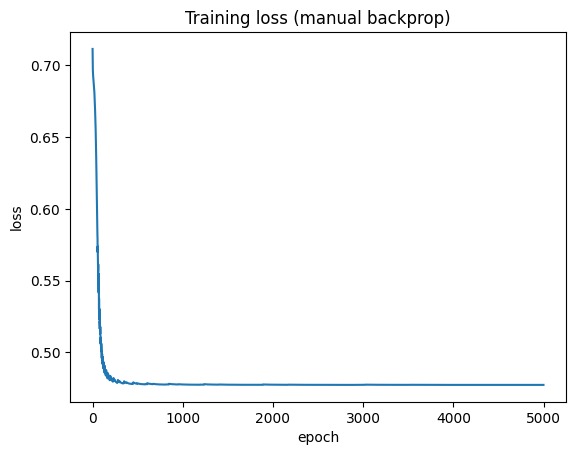

In [10]:
import matplotlib.pyplot as plt
plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Training loss (manual backprop)")
plt.show()

# Autograd

In [11]:
import torch

Xt = torch.tensor(X, dtype=torch.float32)
yt = torch.tensor(y, dtype=torch.float32)

w1 = torch.tensor(W1.copy(), dtype=torch.float32, requires_grad=True)
b1t = torch.tensor(b1.copy(), dtype=torch.float32, requires_grad=True)

w2 = torch.tensor(W2.copy(), dtype=torch.float32, requires_grad=True)
b2t = torch.tensor(b2.copy(), dtype=torch.float32, requires_grad=True)

In [12]:
z1 = Xt @ w1 + b1t
a1 = torch.relu(z1)
z2 = a1 @ w2 + b2t
a2 = torch.sigmoid(z2)

loss = torch.nn.functional.binary_cross_entropy(a2, yt)
print("loss:", loss.item())


loss: 0.4774240255355835


In [13]:
loss.backward()


print("dW1 (autograd):\n", w1.grad.numpy())
print("\ndW1 (manual, from Part 1 first epoch) should match closely if you compare before training")

dW1 (autograd):
 [[-4.33327077e-05  0.00000000e+00 -1.05727100e-04 -1.04609666e-04]
 [-4.33327077e-05  0.00000000e+00 -1.05727100e-04 -1.04609666e-04]]

dW1 (manual, from Part 1 first epoch) should match closely if you compare before training


In [14]:
w1.grad = None
b1t.grad = None
w2.grad = None
b2t.grad = None

# PyTorch Training Pipeline From Scratch

In [15]:
import torch.nn as nn

class TinyNet(nn.Module):
  def __init__(self , n_input , n_hidden , n_output):

    super().__init__()

    self.fc1 = nn.Linear(n_input , n_hidden)
    self.fc2 = nn.Linear(n_hidden , n_output)


  def forward(self, x):
    x = torch.relu(self.fc1(x))
    x = torch.sigmoid(self.fc2(x))

    return x



model = TinyNet(2 , 4, 1)
print(model)

TinyNet(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=1, bias=True)
)


In [16]:
#criterion and optimizer
criterion = nn.BCELoss()

optimizer = torch.optim.SGD(model.parameters() , lr = 0.5)


In [17]:
Xt = torch.tensor(X , dtype = torch.float32)
yt = torch.tensor(y , dtype = torch.float32)


losses_pt = []

for epoch in range(5000):
  optimizer.zero_grad()
  preds = model(Xt)

  loss = criterion(preds , yt)

  loss.backward()

  optimizer.step()

  losses_pt.append(loss.item())

  if epoch % 1000 == 0 :
    print(f"epoch {epoch: 5d} loss {loss.item(): .4f}")


epoch     0 loss  0.7039
epoch  1000 loss  0.0046
epoch  2000 loss  0.0020
epoch  3000 loss  0.0012
epoch  4000 loss  0.0009


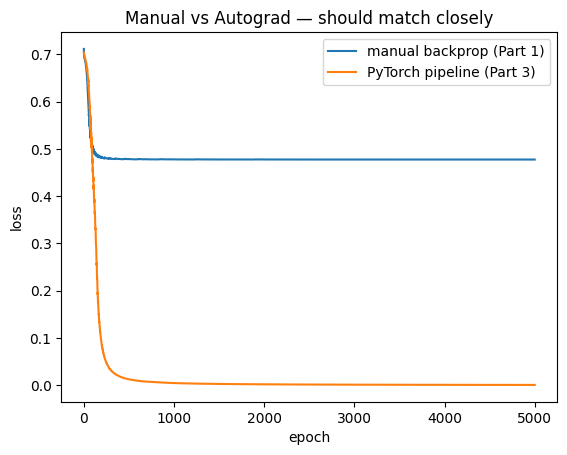

In [18]:
plt.plot(losses, label="manual backprop (Part 1)")
plt.plot(losses_pt, label="PyTorch pipeline (Part 3)")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Manual vs Autograd — should match closely")
plt.show()